# Modular Bayesian modeling for Duolingo SLAM

This notebook parses the English-French SLAM data, builds leakage-safe feature tables, trains an L2 logistic-regression baseline, and fits a hierarchical Bayesian logistic model with mini-batch ADVI.

Feature engineering is modular:

1. The configuration cell contains the single list of enabled feature blocks.
2. Each feature block is defined in its own cell and registers itself on the final line.
3. The build cell applies every enabled block, validates its output, and constructs the numeric and categorical feature lists automatically.

To add or remove a feature family, edit only `ENABLED_FEATURE_BLOCKS`, restart the kernel, and run all cells.


## 1. Configuration


In [1]:
from pathlib import Path
import json
import re
import warnings

import numpy as np
import pandas as pd


DATA_DIR = Path(
    r"C:\Users\Richard\Desktop\school\Bayesian Machine Learning\project\english - french"
)
TRAIN_PATH = DATA_DIR / "fr_en.slam.20190204.train"
DEV_PATH = DATA_DIR / "fr_en.slam.20190204.dev"
DEV_KEY_PATH = DATA_DIR / "fr_en.slam.20190204.dev.key"
PROCESSED_DIR = DATA_DIR / "processed"

RANDOM_SEED = 2026

# This is the only list you edit to turn feature families on or off.
# Order matters when one block uses columns created by another block.
ENABLED_FEATURE_BLOCKS = [
    "linguistic",
    "skill_history",
    "forgetting_curve",
    "causal_user_ability",
    "global_skill_difficulty",
    # "recent_user_performance",
    # "session_fatigue",
]

# Structural Bayesian extensions are kept separate from feature columns.
# Start with an empty list, then test one extension at a time against the
# strong global-skill baseline before combining successful structures.
ENABLED_BAYESIAN_EXTENSIONS = [
     "user_recency_slopes",       # also represents user-specific forgetting
    # "user_format_slopes",
    # "token_pos_hierarchy",
    # "morphology_hierarchy",
    # "token_learning_slopes",
    # "user_skill_mastery_low_rank",
]

USER_SKILL_MASTERY_LATENT_DIM = 2

# Bayesian fitting settings. Reduce these for a quick smoke test.
ADVI_ITERATIONS = 30_000
ADVI_BATCH_SIZE = 8_192
POSTERIOR_DRAWS = 1_000
PREDICTION_CHUNK_SIZE = 5_000

for required_path in [TRAIN_PATH, DEV_PATH, DEV_KEY_PATH]:
    assert required_path.is_file(), f"Missing file: {required_path}"

print("Enabled feature blocks:", ENABLED_FEATURE_BLOCKS)
print("Enabled Bayesian extensions:", ENABLED_BAYESIAN_EXTENSIONS)


Enabled feature blocks: ['linguistic', 'skill_history', 'forgetting_curve', 'causal_user_ability', 'global_skill_difficulty']
Enabled Bayesian extensions: ['user_recency_slopes']


## 2. SLAM parser


In [2]:
"""Parse Duolingo SLAM files into one-row-per-token pandas DataFrames."""

from __future__ import annotations

from pathlib import Path
from typing import Any

import pandas as pd


FIXED_COLUMNS = (
    "instance_id",
    "session_id",
    "exercise_id",
    "exercise_index",
    "token_index",
    "token",
    "token_lower",
    "part_of_speech",
    "morphology",
    "dependency_label",
    "dependency_edge_head",
    "prompt",
    "user",
    "countries",
    "days",
    "client",
    "session",
    "format",
    "time",
    "label",
    "course",
    "split",
)

CATEGORICAL_COLUMNS = (
    "part_of_speech",
    "dependency_label",
    "countries",
    "client",
    "session",
    "format",
    "course",
    "split",
)


def _infer_split(path: Path) -> str:
    """Infer train/dev/test from a standard SLAM filename."""
    name = path.name.lower()
    for split in ("train", "dev", "test"):
        if split in name:
            return split
    return "unknown"


def _infer_course(path: Path) -> str:
    """Infer the course prefix, such as fr_en, from a SLAM filename."""
    first_component = path.name.split(".", maxsplit=1)[0]
    return first_component if "_" in first_component else "unknown"


def _parse_metadata(line: str) -> dict[str, Any]:
    """Parse a non-prompt metadata line beginning with '# '."""
    metadata: dict[str, Any] = {}
    for field in line[2:].split():
        key, value = field.split(":", maxsplit=1)
        if key == "days":
            metadata[key] = float(value)
        elif key == "time":
            metadata[key] = None if value == "null" else int(value)
        else:
            metadata[key] = value
    return metadata


def optimize_slam_dtypes(frame: pd.DataFrame) -> pd.DataFrame:
    """Reduce memory usage while retaining nullable values."""
    for column in CATEGORICAL_COLUMNS:
        if column in frame:
            frame[column] = frame[column].astype("category")

    for column in frame.columns:
        if column.startswith("morph_"):
            if column == "morph_Person":
                frame[column] = pd.to_numeric(frame[column], errors="coerce").astype("Int8")
            else:
                frame[column] = frame[column].astype("category")

    frame["exercise_index"] = frame["exercise_index"].astype("int16")
    frame["token_index"] = frame["token_index"].astype("int16")
    frame["dependency_edge_head"] = frame["dependency_edge_head"].astype("int16")
    frame["days"] = frame["days"].astype("float32")
    frame["time"] = pd.array(frame["time"], dtype="Int32")
    frame["label"] = pd.array(frame["label"], dtype="Int8")
    return frame


def load_slam_dataframe(
    filename: str | Path,
    *,
    split: str | None = None,
    course: str | None = None,
    optimize_dtypes: bool = True,
) -> pd.DataFrame:
    """Load a SLAM train/dev/test file as one row per token.

    The parser retains raw morphology in ``morphology`` and also expands each
    morphological attribute into a ``morph_<name>`` column. Train files carry
    their labels in the final token column; unlabeled dev/test rows receive a
    nullable ``label`` column so all splits share the same schema.
    """
    path = Path(filename)
    if not path.is_file():
        raise FileNotFoundError(path)

    split = split or _infer_split(path)
    course = course or _infer_course(path)
    columns: dict[str, list[Any]] = {column: [] for column in FIXED_COLUMNS}
    morphology_columns: dict[str, list[Any]] = {}
    exercise_metadata: dict[str, Any] = {}
    expected_token_fields: int | None = None

    with path.open("r", encoding="utf-8") as source:
        for line_number, raw_line in enumerate(source, start=1):
            line = raw_line.strip()

            if not line:
                exercise_metadata = {}
                continue

            if line.startswith("# prompt:"):
                exercise_metadata["prompt"] = line.split(":", maxsplit=1)[1]
                continue

            if line.startswith("#"):
                exercise_metadata.update(_parse_metadata(line))
                continue

            fields = line.split()
            if expected_token_fields is None:
                expected_token_fields = len(fields)
                if expected_token_fields not in (6, 7):
                    raise ValueError(
                        f"{path.name}:{line_number}: expected 6 or 7 token fields, "
                        f"found {expected_token_fields}"
                    )
            elif len(fields) != expected_token_fields:
                raise ValueError(
                    f"{path.name}:{line_number}: expected {expected_token_fields} "
                    f"token fields, found {len(fields)}"
                )

            required_metadata = {"user", "countries", "days", "client", "session", "format", "time"}
            missing_metadata = required_metadata - exercise_metadata.keys()
            if missing_metadata:
                raise ValueError(
                    f"{path.name}:{line_number}: token appears before metadata fields "
                    f"{sorted(missing_metadata)}"
                )

            instance_id, token, part_of_speech, morphology, dependency_label, edge_head = fields[:6]
            label = int(fields[6]) if len(fields) == 7 else None
            row_index = len(columns["instance_id"])

            columns["instance_id"].append(instance_id)
            columns["session_id"].append(instance_id[:8])
            columns["exercise_id"].append(instance_id[:10])
            columns["exercise_index"].append(int(instance_id[8:10]))
            columns["token_index"].append(int(instance_id[10:12]))
            columns["token"].append(token)
            columns["token_lower"].append(token.casefold())
            columns["part_of_speech"].append(part_of_speech)
            columns["morphology"].append(morphology)
            columns["dependency_label"].append(dependency_label)
            columns["dependency_edge_head"].append(int(edge_head))
            columns["prompt"].append(exercise_metadata.get("prompt"))
            columns["user"].append(exercise_metadata["user"])
            columns["countries"].append(exercise_metadata["countries"])
            columns["days"].append(exercise_metadata["days"])
            columns["client"].append(exercise_metadata["client"])
            columns["session"].append(exercise_metadata["session"])
            columns["format"].append(exercise_metadata["format"])
            columns["time"].append(exercise_metadata["time"])
            columns["label"].append(label)
            columns["course"].append(course)
            columns["split"].append(split)

            for values in morphology_columns.values():
                values.append(None)

            for item in morphology.split("|"):
                key, value = item.split("=", maxsplit=1)
                column_name = f"morph_{key}"
                if column_name not in morphology_columns:
                    morphology_columns[column_name] = [None] * row_index + [value]
                else:
                    morphology_columns[column_name][-1] = value

    if not columns["instance_id"]:
        raise ValueError(f"No token records found in {path}")

    frame = pd.DataFrame({**columns, **morphology_columns})
    if optimize_dtypes:
        frame = optimize_slam_dtypes(frame)
    return frame


def load_label_file(filename: str | Path) -> pd.Series:
    """Load a SLAM .key or .pred file as an instance-ID-indexed Series."""
    path = Path(filename)
    labels = pd.read_csv(
        path,
        sep=r"\s+",
        names=["instance_id", "label"],
        index_col="instance_id",
        dtype={"instance_id": "string", "label": "float64"},
    )
    if not labels.index.is_unique:
        raise ValueError(f"Duplicate instance IDs in {path}")
    return labels["label"]



## 3. Load immutable raw token tables


In [3]:
train_tokens_raw = load_slam_dataframe(TRAIN_PATH, split="train")
dev_tokens_raw = load_slam_dataframe(DEV_PATH, split="dev")
dev_key = load_label_file(DEV_KEY_PATH)

assert train_tokens_raw["instance_id"].is_unique
assert dev_tokens_raw["instance_id"].is_unique
assert train_tokens_raw["label"].notna().all()
assert dev_tokens_raw["label"].isna().all()
assert set(dev_tokens_raw["instance_id"]) == set(dev_key.index)

print("Train tokens:", train_tokens_raw.shape)
print("Development tokens:", dev_tokens_raw.shape)
print("Training error rate:", f'{train_tokens_raw["label"].mean():.4%}')


Train tokens: (926646, 32)
Development tokens: (137564, 32)
Training error rate: 16.2266%


## 4. Feature registry


In [4]:
from dataclasses import dataclass
from typing import Callable


@dataclass
class FeatureOutput:
    frame: pd.DataFrame
    numeric: tuple[str, ...] = ()
    categorical: tuple[str, ...] = ()


@dataclass
class FeatureBlock:
    name: str
    transform: Callable[[pd.DataFrame], FeatureOutput]
    description: str


# Rerunning this cell deliberately resets the registry.
FEATURE_REGISTRY: dict[str, FeatureBlock] = {}


def register_feature_block(
    name: str,
    transform: Callable[[pd.DataFrame], FeatureOutput],
    description: str,
) -> None:
    """Register or replace one named feature block."""
    FEATURE_REGISTRY[name] = FeatureBlock(
        name=name,
        transform=transform,
        description=description,
    )


def unique_in_order(values):
    """Deduplicate strings without changing their order."""
    return list(dict.fromkeys(values))


## 5A. Linguistic and metadata features

This block also declares model-ready categorical columns. Its final line registers the block.


In [5]:
def make_linguistic_features(dataframe: pd.DataFrame) -> FeatureOutput:
    frame = dataframe.copy()

    token = frame["token"].astype("string")
    prompt = frame["prompt"].astype("string").fillna("")

    frame["skill"] = frame["token_lower"].astype("string")
    frame["token_char_length"] = token.str.len().fillna(0).astype("int16")
    frame["prompt_char_length"] = prompt.str.len().astype("int16")
    frame["prompt_word_count"] = prompt.str.split().str.len().astype("int16")
    frame["morph_feature_count"] = (
        frame["morphology"].astype("string").str.count(r"\|").fillna(-1) + 1
    ).clip(lower=0).astype("int8")

    frame["is_dependency_root"] = (
        frame["dependency_label"].astype("string").eq("ROOT")
        | frame["dependency_edge_head"].eq(0)
    ).astype("int8")

    frame["dependency_distance"] = np.where(
        frame["dependency_edge_head"].eq(0),
        0,
        np.abs(frame["token_index"] - frame["dependency_edge_head"]),
    ).astype("int16")

    frame["is_sentence_initial"] = frame["token_index"].eq(1).astype("int8")
    frame["is_capitalized"] = token.str[0].str.isupper().fillna(False).astype("int8")
    frame["has_digit"] = token.str.contains(r"\d", regex=True, na=False).astype("int8")
    frame["has_non_ascii"] = token.str.contains(
        r"[^\x00-\x7F]", regex=True, na=False
    ).astype("int8")
    frame["days_log1p"] = np.log1p(frame["days"].clip(lower=0)).astype("float32")
    frame["time_missing"] = frame["time"].isna().astype("int8")
    frame["time_log1p"] = np.log1p(
        frame["time"].fillna(0).clip(lower=0)
    ).astype("float32")

    numeric = (
        "token_char_length",
        "prompt_char_length",
        "prompt_word_count",
        "morph_feature_count",
        "is_dependency_root",
        "dependency_distance",
        "is_sentence_initial",
        "is_capitalized",
        "has_digit",
        "has_non_ascii",
        "days_log1p",
        "time_missing",
        "time_log1p",
    )

    categorical = [
        "user",
        "skill",
        "format",
        "client",
        "session",
        "countries",
        "part_of_speech",
        "dependency_label",
    ]
    categorical += [
        column
        for column in frame.columns
        if column.startswith("morph_") and column != "morph_feature_count"
    ]

    for column in categorical:
        frame[column] = (
            frame[column]
            .astype("string")
            .fillna("__MISSING__")
            .astype("category")
        )

    return FeatureOutput(
        frame=frame,
        numeric=tuple(numeric),
        categorical=tuple(categorical),
    )


register_feature_block(
    "linguistic",
    make_linguistic_features,
    "Token, prompt, syntax, morphology, time, and metadata features.",
)


## 5B. Leakage-safe user-skill history

All label-derived values are shifted at the exercise level. Tokens in the current exercise cannot use labels from that exercise.


In [6]:
def make_skill_history_features(
    dataframe: pd.DataFrame,
    alpha: float = 1.0,
    beta: float = 1.0,
) -> FeatureOutput:
    frame = dataframe.copy()
    frame["_skill_history_row"] = np.arange(len(frame), dtype=np.int64)

    keys = ["user", "token_lower", "exercise_id"]

    exercise = (
        frame.groupby(keys, sort=False, observed=True, dropna=False)
        .agg(
            exposure_day=("days", "first"),
            event_order=("_skill_history_row", "min"),
            event_exposures=("instance_id", "size"),
            event_labeled_exposures=("label", "count"),
            event_errors=("label", lambda values: float(values.sum(skipna=True))),
        )
        .reset_index()
        .sort_values(
            ["user", "token_lower", "exposure_day", "event_order"],
            kind="stable",
        )
    )

    groups = exercise.groupby(
        ["user", "token_lower"],
        sort=False,
        observed=True,
        dropna=False,
    )

    exercise["prior_exposures"] = (
        groups["event_exposures"].cumsum() - exercise["event_exposures"]
    )
    exercise["prior_labeled_exposures"] = (
        groups["event_labeled_exposures"].cumsum()
        - exercise["event_labeled_exposures"]
    )
    exercise["prior_errors"] = (
        groups["event_errors"].cumsum() - exercise["event_errors"]
    )

    previous_day = groups["exposure_day"].shift(1)
    exercise["has_prior_exposure"] = previous_day.notna().astype("int8")
    exercise["time_since_last_exposure_days"] = (
        exercise["exposure_day"] - previous_day
    ).clip(lower=0).fillna(0)

    exercise["prior_error_rate"] = (
        exercise["prior_errors"] + alpha
    ) / (
        exercise["prior_labeled_exposures"] + alpha + beta
    )

    exercise["log1p_prior_exposures"] = np.log1p(
        exercise["prior_exposures"]
    )
    exercise["log1p_time_since_last_exposure"] = np.log1p(
        exercise["time_since_last_exposure_days"]
    )

    created = [
        "prior_exposures",
        "prior_labeled_exposures",
        "prior_errors",
        "prior_error_rate",
        "has_prior_exposure",
        "time_since_last_exposure_days",
        "log1p_prior_exposures",
        "log1p_time_since_last_exposure",
    ]

    frame = frame.merge(
        exercise[keys + created],
        on=keys,
        how="left",
        sort=False,
        validate="many_to_one",
    )
    frame = (
        frame.sort_values("_skill_history_row", kind="stable")
        .drop(columns="_skill_history_row")
        .reset_index(drop=True)
    )

    for column in ["prior_exposures", "prior_labeled_exposures", "prior_errors"]:
        frame[column] = frame[column].astype("int32")

    for column in [
        "prior_error_rate",
        "time_since_last_exposure_days",
        "log1p_prior_exposures",
        "log1p_time_since_last_exposure",
    ]:
        frame[column] = frame[column].astype("float32")

    # These are the nonredundant columns supplied to both models.
    numeric = (
        "prior_error_rate",
        "log1p_prior_exposures",
        "log1p_time_since_last_exposure",
        "has_prior_exposure",
    )

    return FeatureOutput(frame=frame, numeric=numeric)


register_feature_block(
    "skill_history",
    make_skill_history_features,
    "Shifted user-token error history, exposure, and forgetting features.",
)


## 5C. Forgetting-curve and exposure-spacing features

These features maintain decayed error/success evidence separately for each user-token pair. State is decayed to the current exercise time before the current labels are observed, so every value is leakage-safe.


In [7]:
def make_forgetting_curve_features(
    dataframe: pd.DataFrame,
) -> FeatureOutput:
    required = {
        "time_since_last_exposure_days",
        "has_prior_exposure",
    }
    missing = required.difference(dataframe.columns)
    if missing:
        raise KeyError(
            "forgetting_curve requires skill_history first; missing "
            f"{sorted(missing)}"
        )

    frame = dataframe.copy()
    frame["_forgetting_row"] = np.arange(len(frame), dtype=np.int64)

    keys = ["user", "token_lower", "exercise_id"]
    events = (
        frame.groupby(keys, sort=False, observed=True, dropna=False)
        .agg(
            exposure_day=("days", "first"),
            event_order=("_forgetting_row", "min"),
            current_labeled_answers=("label", "count"),
            current_errors=(
                "label",
                lambda values: float(values.sum(skipna=True)),
            ),
        )
        .reset_index()
        .sort_values(
            ["user", "token_lower", "exposure_day", "event_order"],
            kind="stable",
        )
        .reset_index(drop=True)
    )

    n_events = len(events)
    decayed_errors_1d = np.zeros(n_events, dtype=np.float32)
    decayed_successes_1d = np.zeros(n_events, dtype=np.float32)
    decayed_errors_7d = np.zeros(n_events, dtype=np.float32)
    decayed_successes_7d = np.zeros(n_events, dtype=np.float32)
    average_spacing = np.zeros(n_events, dtype=np.float32)
    maximum_spacing = np.zeros(n_events, dtype=np.float32)

    for positions in events.groupby(
        ["user", "token_lower"],
        sort=False,
        observed=True,
        dropna=False,
    ).indices.values():
        error_state_1d = 0.0
        success_state_1d = 0.0
        error_state_7d = 0.0
        success_state_7d = 0.0
        previous_day = None
        spacing_sum = 0.0
        spacing_count = 0
        spacing_max = 0.0

        for position in positions:
            current_day = float(events.at[position, "exposure_day"])

            if previous_day is not None:
                gap = max(current_day - previous_day, 0.0)
                decay_1d = np.exp(-gap / 1.0)
                decay_7d = np.exp(-gap / 7.0)

                error_state_1d *= decay_1d
                success_state_1d *= decay_1d
                error_state_7d *= decay_7d
                success_state_7d *= decay_7d

                spacing_sum += gap
                spacing_count += 1
                spacing_max = max(spacing_max, gap)

            # Record state before incorporating labels from this exercise.
            decayed_errors_1d[position] = error_state_1d
            decayed_successes_1d[position] = success_state_1d
            decayed_errors_7d[position] = error_state_7d
            decayed_successes_7d[position] = success_state_7d
            average_spacing[position] = (
                spacing_sum / spacing_count if spacing_count else 0.0
            )
            maximum_spacing[position] = spacing_max

            current_errors = float(events.at[position, "current_errors"])
            current_answers = int(events.at[position, "current_labeled_answers"])
            current_successes = max(current_answers - current_errors, 0.0)

            error_state_1d += current_errors
            success_state_1d += current_successes
            error_state_7d += current_errors
            success_state_7d += current_successes
            previous_day = current_day

    events["decayed_prior_errors_1d"] = decayed_errors_1d
    events["decayed_prior_successes_1d"] = decayed_successes_1d
    events["decayed_prior_errors_7d"] = decayed_errors_7d
    events["decayed_prior_successes_7d"] = decayed_successes_7d
    events["average_exposure_spacing_days"] = average_spacing
    events["maximum_exposure_spacing_days"] = maximum_spacing

    created = [
        "decayed_prior_errors_1d",
        "decayed_prior_successes_1d",
        "decayed_prior_errors_7d",
        "decayed_prior_successes_7d",
        "average_exposure_spacing_days",
        "maximum_exposure_spacing_days",
    ]

    frame = frame.merge(
        events[keys + created],
        on=keys,
        how="left",
        sort=False,
        validate="many_to_one",
    )
    frame = (
        frame.sort_values("_forgetting_row", kind="stable")
        .drop(columns="_forgetting_row")
        .reset_index(drop=True)
    )

    frame["recency_decay_1d"] = (
        frame["has_prior_exposure"]
        * np.exp(-frame["time_since_last_exposure_days"] / 1.0)
    ).astype("float32")
    frame["recency_decay_7d"] = (
        frame["has_prior_exposure"]
        * np.exp(-frame["time_since_last_exposure_days"] / 7.0)
    ).astype("float32")

    for column in created:
        frame[column] = frame[column].astype("float32")
        frame[f"log1p_{column}"] = np.log1p(
            frame[column].clip(lower=0)
        ).astype("float32")

    numeric = (
        "recency_decay_1d",
        "recency_decay_7d",
        "log1p_decayed_prior_errors_1d",
        "log1p_decayed_prior_successes_1d",
        "log1p_decayed_prior_errors_7d",
        "log1p_decayed_prior_successes_7d",
        "log1p_average_exposure_spacing_days",
        "log1p_maximum_exposure_spacing_days",
    )

    return FeatureOutput(frame=frame, numeric=numeric)


register_feature_block(
    "forgetting_curve",
    make_forgetting_curve_features,
    "One- and seven-day decay, decayed outcomes, and exposure spacing.",
)


## 5D. Causal/online user ability

This is a temporally valid historical ability estimate, not a causal treatment-effect estimate. It uses only labels from earlier exercises. Higher `user_ability_log_odds` means lower historical error probability.


In [8]:
def make_causal_user_ability_features(
    dataframe: pd.DataFrame,
    alpha: float = 1.0,
    beta: float = 1.0,
) -> FeatureOutput:
    frame = dataframe.copy()
    frame["_ability_row"] = np.arange(len(frame), dtype=np.int64)

    exercise = (
        frame.groupby(
            ["user", "exercise_id"],
            sort=False,
            observed=True,
            dropna=False,
        )
        .agg(
            exposure_day=("days", "first"),
            event_order=("_ability_row", "min"),
            current_errors=("label", lambda values: float(values.sum(skipna=True))),
            current_labeled_tokens=("label", "count"),
        )
        .reset_index()
        .sort_values(["user", "exposure_day", "event_order"], kind="stable")
    )

    groups = exercise.groupby("user", sort=False, observed=True, dropna=False)
    exercise["user_prior_errors"] = (
        groups["current_errors"].cumsum() - exercise["current_errors"]
    )
    exercise["user_prior_labeled_tokens"] = (
        groups["current_labeled_tokens"].cumsum()
        - exercise["current_labeled_tokens"]
    )

    exercise["user_prior_error_rate"] = (
        exercise["user_prior_errors"] + alpha
    ) / (
        exercise["user_prior_labeled_tokens"] + alpha + beta
    )

    error_probability = exercise["user_prior_error_rate"].clip(1e-6, 1 - 1e-6)
    exercise["user_ability_log_odds"] = np.log(
        (1.0 - error_probability) / error_probability
    )
    exercise["log1p_user_prior_labeled_tokens"] = np.log1p(
        exercise["user_prior_labeled_tokens"]
    )
    exercise["user_has_prior_history"] = (
        exercise["user_prior_labeled_tokens"] > 0
    ).astype("int8")

    created = [
        "user_prior_labeled_tokens",
        "user_prior_errors",
        "user_prior_error_rate",
        "user_ability_log_odds",
        "log1p_user_prior_labeled_tokens",
        "user_has_prior_history",
    ]

    frame = frame.merge(
        exercise[["user", "exercise_id"] + created],
        on=["user", "exercise_id"],
        how="left",
        sort=False,
        validate="many_to_one",
    )
    frame = (
        frame.sort_values("_ability_row", kind="stable")
        .drop(columns="_ability_row")
        .reset_index(drop=True)
    )

    frame["user_prior_labeled_tokens"] = frame[
        "user_prior_labeled_tokens"
    ].astype("int32")
    frame["user_prior_errors"] = frame["user_prior_errors"].astype("float32")

    for column in [
        "user_prior_error_rate",
        "user_ability_log_odds",
        "log1p_user_prior_labeled_tokens",
    ]:
        frame[column] = frame[column].astype("float32")

    numeric = (
        "user_ability_log_odds",
        "log1p_user_prior_labeled_tokens",
        "user_has_prior_history",
    )

    return FeatureOutput(frame=frame, numeric=numeric)


register_feature_block(
    "causal_user_ability",
    make_causal_user_ability_features,
    "Shifted, smoothed user-wide historical ability and evidence features.",
)


## 5E. Causal global skill difficulty

This block estimates token, token-format, and POS-morphology difficulty using only earlier exercises in dataset order. The SLAM files do not contain a shared wall-clock timestamp across users, so dataset order is used as the global prequential order. Development labels remain masked and never update these histories.


In [9]:
def make_global_skill_difficulty_features(
    dataframe: pd.DataFrame,
    alpha: float = 1.0,
    beta: float = 1.0,
) -> FeatureOutput:
    frame = dataframe.copy()
    frame["_global_difficulty_row"] = np.arange(len(frame), dtype=np.int64)

    def build_prior_rate_table(group_columns, prefix):
        """Create one shifted rate table at completed-exercise granularity."""
        event_keys = list(group_columns) + ["user", "exercise_id"]

        events = (
            frame.groupby(
                event_keys,
                sort=False,
                observed=True,
                dropna=False,
            )
            .agg(
                event_order=("_global_difficulty_row", "min"),
                current_labeled_answers=("label", "count"),
                current_errors=(
                    "label",
                    lambda values: float(values.sum(skipna=True)),
                ),
            )
            .reset_index()
            .sort_values("event_order", kind="stable")
            .reset_index(drop=True)
        )

        groups = events.groupby(
            list(group_columns),
            sort=False,
            observed=True,
            dropna=False,
        )

        prior_answers_column = f"{prefix}_prior_labeled_answers"
        prior_errors_column = f"{prefix}_prior_errors"
        prior_rate_column = f"{prefix}_prior_error_rate"
        difficulty_column = f"{prefix}_difficulty_log_odds"

        events[prior_answers_column] = (
            groups["current_labeled_answers"].cumsum()
            - events["current_labeled_answers"]
        )
        events[prior_errors_column] = (
            groups["current_errors"].cumsum()
            - events["current_errors"]
        )
        events[prior_rate_column] = (
            events[prior_errors_column] + alpha
        ) / (
            events[prior_answers_column] + alpha + beta
        )

        rate = events[prior_rate_column].clip(1e-6, 1 - 1e-6)
        events[difficulty_column] = np.log(rate / (1.0 - rate))

        return events, [
            prior_answers_column,
            prior_errors_column,
            prior_rate_column,
            difficulty_column,
        ]

    # Overall token difficulty across all users and formats.
    token_events, token_columns = build_prior_rate_table(
        ["token_lower"],
        "global_token",
    )

    # Count distinct users whose first exposure occurred before this event.
    token_events["_first_user_token_event"] = ~token_events.duplicated(
        ["token_lower", "user"],
        keep="first",
    )
    token_events["_first_user_token_event"] = token_events[
        "_first_user_token_event"
    ].astype("int32")
    token_groups = token_events.groupby(
        "token_lower",
        sort=False,
        observed=True,
        dropna=False,
    )
    token_events["global_token_prior_unique_users"] = (
        token_groups["_first_user_token_event"].cumsum()
        - token_events["_first_user_token_event"]
    )
    token_events["log1p_global_token_prior_unique_users"] = np.log1p(
        token_events["global_token_prior_unique_users"]
    )
    token_columns += [
        "global_token_prior_unique_users",
        "log1p_global_token_prior_unique_users",
    ]

    frame = frame.merge(
        token_events[
            ["token_lower", "user", "exercise_id"] + token_columns
        ],
        on=["token_lower", "user", "exercise_id"],
        how="left",
        sort=False,
        validate="many_to_one",
    )

    # Difficulty specific to the exercise format.
    token_format_events, token_format_columns = build_prior_rate_table(
        ["token_lower", "format"],
        "global_token_format",
    )
    frame = frame.merge(
        token_format_events[
            ["token_lower", "format", "user", "exercise_id"]
            + token_format_columns
        ],
        on=["token_lower", "format", "user", "exercise_id"],
        how="left",
        sort=False,
        validate="many_to_one",
    )

    # Difficulty for a linguistic construction rather than a specific token.
    pos_morph_events, pos_morph_columns = build_prior_rate_table(
        ["part_of_speech", "morphology"],
        "global_pos_morph",
    )
    frame = frame.merge(
        pos_morph_events[
            [
                "part_of_speech",
                "morphology",
                "user",
                "exercise_id",
            ]
            + pos_morph_columns
        ],
        on=[
            "part_of_speech",
            "morphology",
            "user",
            "exercise_id",
        ],
        how="left",
        sort=False,
        validate="many_to_one",
    )

    frame = (
        frame.sort_values("_global_difficulty_row", kind="stable")
        .drop(columns="_global_difficulty_row")
        .reset_index(drop=True)
    )

    all_rate_columns = token_columns + token_format_columns + pos_morph_columns
    for column in all_rate_columns:
        if (
            column.endswith("_prior_labeled_answers")
            or column == "global_token_prior_unique_users"
        ):
            frame[column] = frame[column].astype("int32")
        else:
            frame[column] = frame[column].astype("float32")

    frame["log1p_global_token_prior_unique_users"] = frame[
        "log1p_global_token_prior_unique_users"
    ].astype("float32")

    # Log-odds are natural linear-predictor inputs; the raw rates remain in
    # the feature table for interpretation and diagnostics.
    numeric = (
        "global_token_difficulty_log_odds",
        "global_token_format_difficulty_log_odds",
        "global_pos_morph_difficulty_log_odds",
        "log1p_global_token_prior_unique_users",
    )

    return FeatureOutput(frame=frame, numeric=numeric)


register_feature_block(
    "global_skill_difficulty",
    make_global_skill_difficulty_features,
    "Prequential global token and linguistic-construction difficulty.",
)


## 5F. Recent user performance and streaks

The 10- and 50-answer windows contain labeled tokens from completed earlier exercises only. The correct/error streak is the streak entering the current exercise. All tokens in an exercise receive the same prior values, preventing within-exercise leakage.


In [10]:
from collections import deque


def make_recent_user_performance_features(
    dataframe: pd.DataFrame,
    alpha: float = 1.0,
    beta: float = 1.0,
) -> FeatureOutput:
    frame = dataframe.copy()
    frame["_recent_row"] = np.arange(len(frame), dtype=np.int64)

    exercise = (
        frame.groupby(
            ["user", "exercise_id"],
            sort=False,
            observed=True,
            dropna=False,
        )
        .agg(
            exposure_day=("days", "first"),
            event_order=("_recent_row", "min"),
            exercise_labels=(
                "label",
                lambda values: tuple(
                    values.dropna().astype("int8").tolist()
                ),
            ),
        )
        .reset_index()
        .sort_values(
            ["user", "exposure_day", "event_order"],
            kind="stable",
        )
        .reset_index(drop=True)
    )

    n_exercises = len(exercise)
    last_10_rate = np.empty(n_exercises, dtype=np.float32)
    last_50_rate = np.empty(n_exercises, dtype=np.float32)
    last_10_available = np.empty(n_exercises, dtype=np.int8)
    last_50_available = np.empty(n_exercises, dtype=np.int8)
    correct_streak = np.empty(n_exercises, dtype=np.int32)
    error_streak = np.empty(n_exercises, dtype=np.int32)

    # There are only about 1,200 users, so maintaining a small deque for each
    # user's chronologically ordered exercises is efficient and transparent.
    for positions in exercise.groupby(
        "user", sort=False, observed=True, dropna=False
    ).indices.values():
        recent_answers = deque(maxlen=50)
        previous_outcome = None
        streak_length = 0

        for position in positions:
            recent_values = list(recent_answers)
            values_10 = recent_values[-10:]

            count_10 = len(values_10)
            count_50 = len(recent_values)

            last_10_available[position] = count_10
            last_50_available[position] = count_50
            last_10_rate[position] = (
                sum(values_10) + alpha
            ) / (
                count_10 + alpha + beta
            )
            last_50_rate[position] = (
                sum(recent_values) + alpha
            ) / (
                count_50 + alpha + beta
            )

            correct_streak[position] = (
                streak_length if previous_outcome == 0 else 0
            )
            error_streak[position] = (
                streak_length if previous_outcome == 1 else 0
            )

            # Update only after recording the current exercise's features.
            # Development labels are missing, so they never enter this state.
            for outcome in exercise.at[position, "exercise_labels"]:
                outcome = int(outcome)
                if previous_outcome == outcome:
                    streak_length += 1
                else:
                    previous_outcome = outcome
                    streak_length = 1
                recent_answers.append(outcome)

    exercise["user_last_10_answers_available"] = last_10_available
    exercise["user_last_50_answers_available"] = last_50_available
    exercise["user_last_10_error_rate"] = last_10_rate
    exercise["user_last_50_error_rate"] = last_50_rate
    exercise["user_entering_correct_streak"] = correct_streak
    exercise["user_entering_error_streak"] = error_streak
    exercise["log1p_user_entering_correct_streak"] = np.log1p(
        correct_streak
    ).astype("float32")
    exercise["log1p_user_entering_error_streak"] = np.log1p(
        error_streak
    ).astype("float32")

    created = [
        "user_last_10_answers_available",
        "user_last_50_answers_available",
        "user_last_10_error_rate",
        "user_last_50_error_rate",
        "user_entering_correct_streak",
        "user_entering_error_streak",
        "log1p_user_entering_correct_streak",
        "log1p_user_entering_error_streak",
    ]

    frame = frame.merge(
        exercise[["user", "exercise_id"] + created],
        on=["user", "exercise_id"],
        how="left",
        sort=False,
        validate="many_to_one",
    )
    frame = (
        frame.sort_values("_recent_row", kind="stable")
        .drop(columns="_recent_row")
        .reset_index(drop=True)
    )

    numeric = (
        "user_last_10_error_rate",
        "user_last_50_error_rate",
        "log1p_user_entering_correct_streak",
        "log1p_user_entering_error_streak",
    )

    return FeatureOutput(frame=frame, numeric=numeric)


register_feature_block(
    "recent_user_performance",
    make_recent_user_performance_features,
    "Shifted 10/50-answer user error rates and entering streak lengths.",
)


## 5G. Optional session/fatigue features

This block is registered but disabled in the configuration cell. It excludes current-exercise completion time, keeping the feature set valid for prediction before the current response.


In [11]:
def make_session_fatigue_features(
    dataframe: pd.DataFrame,
    alpha: float = 1.0,
    beta: float = 1.0,
) -> FeatureOutput:
    frame = dataframe.copy()
    frame["_session_row"] = np.arange(len(frame), dtype=np.int64)

    keys = ["user", "session_id", "exercise_id"]
    exercise = (
        frame.groupby(keys, sort=False, observed=True, dropna=False)
        .agg(
            event_order=("_session_row", "min"),
            exposure_day=("days", "first"),
            exercise_time_seconds=("time", "first"),
            exercise_token_count=("instance_id", "size"),
            current_labeled_tokens=("label", "count"),
            current_errors=("label", lambda values: float(values.sum(skipna=True))),
        )
        .reset_index()
        .sort_values(
            ["user", "session_id", "exposure_day", "event_order"],
            kind="stable",
        )
    )

    groups = exercise.groupby(
        ["user", "session_id"],
        sort=False,
        observed=True,
        dropna=False,
    )

    exercise["exercise_position_in_session"] = groups.cumcount() + 1
    exercise["has_previous_exercise"] = (
        exercise["exercise_position_in_session"] > 1
    ).astype("int8")
    exercise["prior_tokens_in_session"] = (
        groups["exercise_token_count"].cumsum()
        - exercise["exercise_token_count"]
    )
    exercise["prior_labeled_tokens_in_session"] = (
        groups["current_labeled_tokens"].cumsum()
        - exercise["current_labeled_tokens"]
    )
    exercise["prior_errors_in_session"] = (
        groups["current_errors"].cumsum() - exercise["current_errors"]
    )
    exercise["session_prior_error_rate"] = (
        exercise["prior_errors_in_session"] + alpha
    ) / (
        exercise["prior_labeled_tokens_in_session"] + alpha + beta
    )

    exercise["previous_exercise_time_seconds"] = groups[
        "exercise_time_seconds"
    ].shift(1)

    time_filled = exercise["exercise_time_seconds"].fillna(0).astype("float64")
    exercise["_time_filled"] = time_filled
    exercise["cumulative_session_time_before_seconds"] = (
        exercise.groupby(
            ["user", "session_id"], sort=False, observed=True, dropna=False
        )["_time_filled"].cumsum()
        - exercise["_time_filled"]
    )

    current_error_rate = (
        exercise["current_errors"]
        / exercise["current_labeled_tokens"].replace(0, np.nan)
    )
    exercise["_current_error_rate"] = current_error_rate
    exercise["previous_exercise_error_rate"] = exercise.groupby(
        ["user", "session_id"], sort=False, observed=True, dropna=False
    )["_current_error_rate"].shift(1)

    exercise["log1p_exercise_position_in_session"] = np.log1p(
        exercise["exercise_position_in_session"]
    )
    exercise["log1p_prior_tokens_in_session"] = np.log1p(
        exercise["prior_tokens_in_session"]
    )
    exercise["log1p_cumulative_session_time_before"] = np.log1p(
        exercise["cumulative_session_time_before_seconds"].clip(lower=0)
    )

    created = [
        "exercise_token_count",
        "exercise_position_in_session",
        "has_previous_exercise",
        "prior_tokens_in_session",
        "prior_labeled_tokens_in_session",
        "prior_errors_in_session",
        "session_prior_error_rate",
        "previous_exercise_time_seconds",
        "cumulative_session_time_before_seconds",
        "previous_exercise_error_rate",
        "log1p_exercise_position_in_session",
        "log1p_prior_tokens_in_session",
        "log1p_cumulative_session_time_before",
    ]

    frame = frame.merge(
        exercise[keys + created],
        on=keys,
        how="left",
        sort=False,
        validate="many_to_one",
    )
    frame = (
        frame.sort_values("_session_row", kind="stable")
        .drop(columns="_session_row")
        .reset_index(drop=True)
    )

    numeric = (
        "exercise_token_count",
        "log1p_exercise_position_in_session",
        "log1p_prior_tokens_in_session",
        "session_prior_error_rate",
        "has_previous_exercise",
        "log1p_cumulative_session_time_before",
        "previous_exercise_time_seconds",
        "previous_exercise_error_rate",
    )

    return FeatureOutput(frame=frame, numeric=numeric)


register_feature_block(
    "session_fatigue",
    make_session_fatigue_features,
    "Within-session position, prior performance, and prior timing features.",
)


## 6. Apply every enabled feature block


In [12]:
def build_feature_tables(
    train_raw: pd.DataFrame,
    dev_raw: pd.DataFrame,
    enabled_blocks: list[str],
):
    """Build fresh feature tables without mutating the raw inputs."""
    missing_blocks = [
        name for name in enabled_blocks if name not in FEATURE_REGISTRY
    ]
    if missing_blocks:
        raise KeyError(f"Unregistered feature blocks: {missing_blocks}")

    train = train_raw.copy()
    dev = dev_raw.copy()

    # Development outcomes are deliberately unavailable during feature creation.
    dev["label"] = pd.array([pd.NA] * len(dev), dtype="Int8")
    assert dev["label"].isna().all()

    train["_partition"] = "train"
    dev["_partition"] = "dev"
    combined = pd.concat([train, dev], ignore_index=True)

    expected_ids = combined["instance_id"].astype("string").reset_index(drop=True)
    numeric = []
    categorical = []

    print("Applying feature blocks:")
    for name in enabled_blocks:
        block = FEATURE_REGISTRY[name]
        result = block.transform(combined)

        if not isinstance(result, FeatureOutput):
            raise TypeError(f'{name!r} did not return FeatureOutput')
        if len(result.frame) != len(combined):
            raise ValueError(f'{name!r} changed the row count')
        if not result.frame["instance_id"].astype("string").reset_index(
            drop=True
        ).equals(expected_ids):
            raise ValueError(f'{name!r} changed token row order')

        combined = result.frame
        numeric.extend(result.numeric)
        categorical.extend(result.categorical)
        print(f"  {name}: +{len(result.numeric)} numeric, "
              f"+{len(result.categorical)} categorical")

    numeric = unique_in_order(numeric)
    categorical = unique_in_order(categorical)

    overlap = set(numeric).intersection(categorical)
    if overlap:
        raise ValueError(f"Features declared as both numeric and categorical: {overlap}")

    missing_columns = [
        column
        for column in numeric + categorical
        if column not in combined.columns
    ]
    if missing_columns:
        raise KeyError(f"Declared features not found: {missing_columns}")

    train_features = (
        combined.loc[combined["_partition"].eq("train")]
        .drop(columns="_partition")
        .reset_index(drop=True)
    )
    dev_features = (
        combined.loc[combined["_partition"].eq("dev")]
        .drop(columns="_partition")
        .reset_index(drop=True)
    )

    assert train_features["label"].notna().all()
    assert dev_features["label"].isna().all()

    return train_features, dev_features, numeric, categorical


(
    train_features,
    dev_features,
    numeric_feature_columns,
    categorical_feature_columns,
) = build_feature_tables(
    train_tokens_raw,
    dev_tokens_raw,
    ENABLED_FEATURE_BLOCKS,
)

print("\nTraining shape:", train_features.shape)
print("Development shape:", dev_features.shape)
print("Numeric features:", len(numeric_feature_columns))
print("Categorical features:", len(categorical_feature_columns))
print("Numeric feature list:", numeric_feature_columns)


Applying feature blocks:
  linguistic: +13 numeric, +18 categorical
  skill_history: +4 numeric, +0 categorical
  forgetting_curve: +8 numeric, +0 categorical
  causal_user_ability: +3 numeric, +0 categorical
  global_skill_difficulty: +4 numeric, +0 categorical

Training shape: (926646, 88)
Development shape: (137564, 88)
Numeric features: 32
Categorical features: 18
Numeric feature list: ['token_char_length', 'prompt_char_length', 'prompt_word_count', 'morph_feature_count', 'is_dependency_root', 'dependency_distance', 'is_sentence_initial', 'is_capitalized', 'has_digit', 'has_non_ascii', 'days_log1p', 'time_missing', 'time_log1p', 'prior_error_rate', 'log1p_prior_exposures', 'log1p_time_since_last_exposure', 'has_prior_exposure', 'recency_decay_1d', 'recency_decay_7d', 'log1p_decayed_prior_errors_1d', 'log1p_decayed_prior_successes_1d', 'log1p_decayed_prior_errors_7d', 'log1p_decayed_prior_successes_7d', 'log1p_average_exposure_spacing_days', 'log1p_maximum_exposure_spacing_days', 'u

## 7. Validate leakage-safe features


In [13]:
assert len(train_features) == len(train_tokens_raw)
assert len(dev_features) == len(dev_tokens_raw)
assert train_features["instance_id"].equals(train_tokens_raw["instance_id"])
assert dev_features["instance_id"].equals(dev_tokens_raw["instance_id"])

if "skill_history" in ENABLED_FEATURE_BLOCKS:
    assert train_features["prior_error_rate"].between(0, 1).all()
    cold_skill = train_features["prior_exposures"].eq(0)
    assert train_features.loc[cold_skill, "prior_errors"].eq(0).all()

if "forgetting_curve" in ENABLED_FEATURE_BLOCKS:
    assert train_features["recency_decay_1d"].between(0, 1).all()
    assert train_features["recency_decay_7d"].between(0, 1).all()
    assert train_features["decayed_prior_errors_7d"].ge(0).all()
    assert train_features["decayed_prior_successes_7d"].ge(0).all()
    assert train_features["average_exposure_spacing_days"].ge(0).all()
    assert train_features["maximum_exposure_spacing_days"].ge(0).all()

if "causal_user_ability" in ENABLED_FEATURE_BLOCKS:
    assert train_features["user_prior_error_rate"].between(0, 1).all()
    cold_user = train_features["user_prior_labeled_tokens"].eq(0)
    assert train_features.loc[cold_user, "user_prior_errors"].eq(0).all()
    assert train_features.loc[cold_user, "user_ability_log_odds"].eq(0).all()

if "global_skill_difficulty" in ENABLED_FEATURE_BLOCKS:
    for column in [
        "global_token_prior_error_rate",
        "global_token_format_prior_error_rate",
        "global_pos_morph_prior_error_rate",
    ]:
        assert train_features[column].between(0, 1).all()
    assert train_features["global_token_prior_unique_users"].ge(0).all()

if "recent_user_performance" in ENABLED_FEATURE_BLOCKS:
    assert train_features["user_last_10_error_rate"].between(0, 1).all()
    assert train_features["user_last_50_error_rate"].between(0, 1).all()
    assert train_features["user_entering_correct_streak"].ge(0).all()
    assert train_features["user_entering_error_streak"].ge(0).all()

preview_columns = [
    "instance_id",
    "user",
    "token",
    "label",
] + [
    column
    for column in [
        "prior_error_rate",
        "log1p_prior_exposures",
        "recency_decay_1d",
        "recency_decay_7d",
        "decayed_prior_errors_7d",
        "decayed_prior_successes_7d",
        "average_exposure_spacing_days",
        "maximum_exposure_spacing_days",
        "user_prior_error_rate",
        "user_ability_log_odds",
        "global_token_prior_error_rate",
        "global_token_format_prior_error_rate",
        "global_pos_morph_prior_error_rate",
        "global_token_prior_unique_users",
        "user_last_10_error_rate",
        "user_last_50_error_rate",
        "user_entering_correct_streak",
        "user_entering_error_streak",
    ]
    if column in train_features.columns
]

display(train_features[preview_columns].head(20))


,instance_id,user,token,label,prior_error_rate,log1p_prior_exposures,recency_decay_1d,recency_decay_7d,decayed_prior_errors_7d,decayed_prior_successes_7d,average_exposure_spacing_days,maximum_exposure_spacing_days,user_prior_error_rate,user_ability_log_odds,global_token_prior_error_rate,global_token_format_prior_error_rate,global_pos_morph_prior_error_rate,global_token_prior_unique_users
0,8XTyQUAl0101,YjS/mQOx,Le,0,0.500000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000,0.500000,0.000000,0.500000,0.500000,0.500000,0
1,8XTyQUAl0102,YjS/mQOx,garçon,0,0.500000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000,0.500000,0.000000,0.500000,0.500000,0.500000,0
2,8XTyQUAl0201,YjS/mQOx,Je,0,0.500000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000,0.250000,1.098612,0.500000,0.500000,0.500000,0
3,8XTyQUAl0202,YjS/mQOx,suis,0,0.500000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000,0.250000,1.098612,0.500000,0.500000,0.500000,0
4,8XTyQUAl0203,YjS/mQOx,une,0,0.500000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000,0.250000,1.098612,0.500000,0.500000,0.500000,0
5,8XTyQUAl0204,YjS/mQOx,femme,0,0.500000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000,0.250000,1.098612,0.500000,0.500000,0.500000,0
6,8XTyQUAl0301,YjS/mQOx,La,0,0.500000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000,0.125000,1.945910,0.500000,0.500000,0.500000,0
7,8XTyQUAl0302,YjS/mQOx,fille,0,0.500000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000,0.125000,1.945910,0.500000,0.500000,0.333333,0
8,8XTyQUAl0401,YjS/mQOx,Je,0,0.333333,0.693147,1.000000,1.000000,0.0,1.000000,0.000000,0.000,0.100000,2.197225,0.333333,0.333333,0.333333,1
9,8XTyQUAl0402,YjS/mQOx,suis,0,0.333333,0.693147,1.000000,1.000000,0.0,1.000000,0.000000,0.000,0.100000,2.197225,0.333333,0.333333,0.333333,1


## 8. Save Parquet feature tables and manifest


In [14]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_FEATURE_PATH = PROCESSED_DIR / "fr_en_train_features.parquet"
DEV_FEATURE_PATH = PROCESSED_DIR / "fr_en_dev_features.parquet"
DEV_LABEL_PATH = PROCESSED_DIR / "fr_en_dev_labels.parquet"
FEATURE_MANIFEST_PATH = PROCESSED_DIR / "fr_en_feature_manifest.json"

dev_labels = dev_features["instance_id"].map(dev_key)
assert dev_labels.notna().all()

train_features.to_parquet(TRAIN_FEATURE_PATH, index=False)
dev_features.to_parquet(DEV_FEATURE_PATH, index=False)
pd.DataFrame(
    {
        "instance_id": dev_features["instance_id"],
        "label": dev_labels.astype("int8"),
    }
).to_parquet(DEV_LABEL_PATH, index=False)

feature_manifest = {
    "enabled_feature_blocks": ENABLED_FEATURE_BLOCKS,
    "enabled_bayesian_extensions": ENABLED_BAYESIAN_EXTENSIONS,
    "numeric_features": numeric_feature_columns,
    "categorical_features": categorical_feature_columns,
}
FEATURE_MANIFEST_PATH.write_text(
    json.dumps(feature_manifest, indent=2),
    encoding="utf-8",
)

print(TRAIN_FEATURE_PATH)
print(DEV_FEATURE_PATH)
print(FEATURE_MANIFEST_PATH)


C:\Users\Richard\Desktop\school\Bayesian Machine Learning\project\english - french\processed\fr_en_train_features.parquet
C:\Users\Richard\Desktop\school\Bayesian Machine Learning\project\english - french\processed\fr_en_dev_features.parquet
C:\Users\Richard\Desktop\school\Bayesian Machine Learning\project\english - french\processed\fr_en_feature_manifest.json


## 9. L2 logistic-regression baseline


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import joblib


numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler(with_mean=False)),
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "one_hot",
            OneHotEncoder(
                handle_unknown="infrequent_if_exist",
                min_frequency=5,
                dtype=np.float32,
            ),
        ),
    ]
)

l2_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_feature_columns),
        ("categorical", categorical_pipeline, categorical_feature_columns),
    ],
    sparse_threshold=1.0,
)

l2_model = Pipeline(
    steps=[
        ("preprocessor", l2_preprocessor),
        (
            "classifier",
            LogisticRegression(
                penalty="l2",
                C=1.0,
                solver="saga",
                max_iter=200,
                random_state=RANDOM_SEED,
                verbose=0,
            ),
        ),
    ]
)

X_train_l2 = train_features[numeric_feature_columns + categorical_feature_columns]
X_dev_l2 = dev_features[numeric_feature_columns + categorical_feature_columns]
y_train = train_features["label"].to_numpy(dtype=np.int32)
y_dev = dev_labels.to_numpy(dtype=np.int32)

l2_model.fit(X_train_l2, y_train)
l2_probability = l2_model.predict_proba(X_dev_l2)[:, 1]

print(f"L2 AUROC: {roc_auc_score(y_dev, l2_probability):.6f}")
print(f"L2 PR-AUC: {average_precision_score(y_dev, l2_probability):.6f}")
print(f"L2 Brier:  {brier_score_loss(y_dev, l2_probability):.6f}")


C:\Users\Richard\anaconda3\envs\tf_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Richard\anaconda3\envs\tf_env\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


L2 AUROC: 0.801654
L2 PR-AUC: 0.516620
L2 Brier:  0.114605


In [16]:
L2_MODEL_PATH = PROCESSED_DIR / "fr_en_l2_logistic.joblib"
L2_PREDICTION_PATH = PROCESSED_DIR / "fr_en_dev_l2_predictions.parquet"
L2_PRED_PATH = PROCESSED_DIR / "fr_en_dev_l2.pred"

joblib.dump(l2_model, L2_MODEL_PATH)

l2_predictions = pd.DataFrame(
    {
        "instance_id": dev_features["instance_id"],
        "label": y_dev,
        "probability": l2_probability,
    }
)
l2_predictions.to_parquet(L2_PREDICTION_PATH, index=False)
l2_predictions[["instance_id", "probability"]].to_csv(
    L2_PRED_PATH,
    sep=" ",
    header=False,
    index=False,
)

print(L2_PREDICTION_PATH)


C:\Users\Richard\Desktop\school\Bayesian Machine Learning\project\english - french\processed\fr_en_dev_l2_predictions.parquet


## 10. Hierarchical Bayesian logistic regression

All registered numeric features are standardized and used automatically. Every registered categorical feature receives a zero-centered effect. `user` and `skill` receive hierarchical scale priors; the remaining categorical effects use regularizing Normal priors.

The development labels remain separate and are used only after predictions have been generated.


In [17]:
import arviz as az
import pymc as pm
import pytensor.tensor as pt
from scipy.special import expit


def safe_name(value: str) -> str:
    return re.sub(r"[^0-9a-zA-Z_]+", "_", value)


# Numeric preprocessing is learned from training data only.
bayes_numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

X_train_bayes = bayes_numeric_pipeline.fit_transform(
    train_features[numeric_feature_columns]
).astype(np.float32)
X_dev_bayes = bayes_numeric_pipeline.transform(
    dev_features[numeric_feature_columns]
).astype(np.float32)
y_train_bayes = train_features["label"].to_numpy(dtype=np.int32)


def encode_categories(train_frame, dev_frame, columns):
    train_indices = {}
    dev_indices = {}
    levels = {}

    for column in columns:
        train_values = train_frame[column].astype("string").fillna("__MISSING__")
        dev_values = dev_frame[column].astype("string").fillna("__MISSING__")

        known_levels = pd.Index(train_values.unique()).astype(str).tolist()
        mapping = {value: index + 1 for index, value in enumerate(known_levels)}

        # Index zero is reserved for unseen development categories.
        train_indices[column] = (
            train_values.map(mapping).fillna(0).to_numpy(dtype=np.int32)
        )
        dev_indices[column] = (
            dev_values.map(mapping).fillna(0).to_numpy(dtype=np.int32)
        )
        levels[column] = known_levels

    return train_indices, dev_indices, levels


(
    train_category_indices,
    dev_category_indices,
    category_levels,
) = encode_categories(
    train_features,
    dev_features,
    categorical_feature_columns,
)

category_safe_names = {
    column: safe_name(column) for column in categorical_feature_columns
}

VALID_BAYESIAN_EXTENSIONS = {
    "user_recency_slopes",
    "user_format_slopes",
    "token_pos_hierarchy",
    "morphology_hierarchy",
    "token_learning_slopes",
    "user_skill_mastery_low_rank",
}
unknown_extensions = set(ENABLED_BAYESIAN_EXTENSIONS).difference(
    VALID_BAYESIAN_EXTENSIONS
)
if unknown_extensions:
    raise KeyError(f"Unknown Bayesian extensions: {sorted(unknown_extensions)}")

numeric_feature_index = {
    column: index for index, column in enumerate(numeric_feature_columns)
}

if "user_recency_slopes" in ENABLED_BAYESIAN_EXTENSIONS:
    if "log1p_time_since_last_exposure" not in numeric_feature_index:
        raise KeyError("user_recency_slopes requires skill_history")

if "token_learning_slopes" in ENABLED_BAYESIAN_EXTENSIONS:
    if "log1p_prior_exposures" not in numeric_feature_index:
        raise KeyError("token_learning_slopes requires skill_history")

required_categorical = {"user", "skill", "format", "part_of_speech"}
missing_categorical = required_categorical.difference(categorical_feature_columns)
if missing_categorical and ENABLED_BAYESIAN_EXTENSIONS:
    raise KeyError(
        "Bayesian extensions require linguistic categorical features; missing "
        f"{sorted(missing_categorical)}"
    )

# Map each token to its most frequently observed POS for POS-grouped token
# shrinkage. This mapping is learned from training data only.
skill_pos_index = None
skill_pos_levels = None
if "token_pos_hierarchy" in ENABLED_BAYESIAN_EXTENSIONS:
    modal_pos_by_skill = (
        train_features[["skill", "part_of_speech"]]
        .assign(
            skill=lambda data: data["skill"].astype("string"),
            part_of_speech=lambda data: data["part_of_speech"].astype("string"),
        )
        .groupby("skill", sort=False, observed=True)["part_of_speech"]
        .agg(lambda values: values.value_counts().index[0])
    )
    skill_pos_levels = category_levels["part_of_speech"]
    pos_to_index = {
        value: index for index, value in enumerate(skill_pos_levels)
    }
    fallback_pos_index = pos_to_index.get("__MISSING__", 0)
    skill_pos_index = np.asarray(
        [
            pos_to_index.get(
                str(modal_pos_by_skill.get(skill, "__MISSING__")),
                fallback_pos_index,
            )
            for skill in category_levels["skill"]
        ],
        dtype=np.int32,
    )

print("Bayesian numeric features:", len(numeric_feature_columns))
print("Bayesian categorical effects:", len(categorical_feature_columns))
print("Bayesian extensions:", ENABLED_BAYESIAN_EXTENSIONS)


Bayesian numeric features: 32
Bayesian categorical effects: 18
Bayesian extensions: ['user_recency_slopes']


In [18]:
coords = {
    "numeric_feature": numeric_feature_columns,
}

for column in categorical_feature_columns:
    safe = category_safe_names[column]
    coords[f"{safe}_level"] = ["__UNSEEN__"] + category_levels[column]
    coords[f"{safe}_known_level"] = category_levels[column]

if "token_pos_hierarchy" in ENABLED_BAYESIAN_EXTENSIONS:
    coords["skill_pos_group"] = skill_pos_levels

if "user_skill_mastery_low_rank" in ENABLED_BAYESIAN_EXTENSIONS:
    coords["mastery_latent_dimension"] = list(
        range(USER_SKILL_MASTERY_LATENT_DIM)
    )

minibatch_inputs = [
    X_train_bayes,
    y_train_bayes,
] + [
    train_category_indices[column]
    for column in categorical_feature_columns
]

with pm.Model(coords=coords) as bayesian_model:
    minibatches = pm.Minibatch(
        *minibatch_inputs,
        batch_size=ADVI_BATCH_SIZE,
    )
    X_minibatch = minibatches[0]
    y_minibatch = minibatches[1]
    category_minibatches = {
        column: minibatches[index + 2]
        for index, column in enumerate(categorical_feature_columns)
    }

    intercept = pm.Normal("intercept", mu=0.0, sigma=1.5)
    beta = pm.Normal(
        "beta",
        mu=0.0,
        sigma=0.5,
        dims="numeric_feature",
    )

    linear_predictor = intercept + pt.dot(X_minibatch, beta)

    for column in categorical_feature_columns:
        safe = category_safe_names[column]
        known_dimension = f"{safe}_known_level"
        full_dimension = f"{safe}_level"

        offset = pm.Normal(
            f"{safe}_offset",
            mu=0.0,
            sigma=1.0,
            dims=known_dimension,
        )
        centered_offset = offset - pt.mean(offset)

        if (
            column == "skill"
            and "token_pos_hierarchy" in ENABLED_BAYESIAN_EXTENSIONS
        ):
            # POS-specific scales pool token deviations within linguistic groups.
            skill_pos_scale = pm.HalfNormal(
                "skill_pos_scale",
                sigma=1.0,
                dims="skill_pos_group",
            )
            known_effect = (
                skill_pos_scale[skill_pos_index] * centered_offset
            )
        elif column in {"user", "skill"}:
            effect_scale = pm.HalfNormal(
                f"{safe}_scale",
                sigma=1.0,
            )
            known_effect = effect_scale * centered_offset
        elif (
            column.startswith("morph_")
            and "morphology_hierarchy" in ENABLED_BAYESIAN_EXTENSIONS
        ):
            morphology_scale = pm.HalfNormal(
                f"{safe}_scale",
                sigma=0.5,
            )
            known_effect = morphology_scale * centered_offset
        else:
            known_effect = 0.5 * centered_offset

        # An unseen development level receives a neutral zero effect.
        full_effect = pm.Deterministic(
            f"{safe}_effect",
            pt.concatenate([pt.zeros(1), known_effect]),
            dims=full_dimension,
        )

        linear_predictor = (
            linear_predictor
            + full_effect[category_minibatches[column]]
        )

    # Random recency slopes by user are the user-specific forgetting-rate
    # extension. The global recency coefficient remains in beta.
    if "user_recency_slopes" in ENABLED_BAYESIAN_EXTENSIONS:
        recency_index = numeric_feature_index[
            "log1p_time_since_last_exposure"
        ]
        user_recency_offset = pm.Normal(
            "user_recency_offset",
            mu=0.0,
            sigma=1.0,
            dims="user_known_level",
        )
        user_recency_scale = pm.HalfNormal(
            "user_recency_scale",
            sigma=0.5,
        )
        known_user_recency_slope = user_recency_scale * (
            user_recency_offset - pt.mean(user_recency_offset)
        )
        user_recency_slope = pm.Deterministic(
            "user_recency_slope",
            pt.concatenate([pt.zeros(1), known_user_recency_slope]),
            dims="user_level",
        )
        linear_predictor += (
            user_recency_slope[category_minibatches["user"]]
            * X_minibatch[:, recency_index]
        )

    # A random exposure slope lets tokens differ in their learning rate.
    if "token_learning_slopes" in ENABLED_BAYESIAN_EXTENSIONS:
        exposure_index = numeric_feature_index["log1p_prior_exposures"]
        token_learning_offset = pm.Normal(
            "token_learning_offset",
            mu=0.0,
            sigma=1.0,
            dims="skill_known_level",
        )
        token_learning_scale = pm.HalfNormal(
            "token_learning_scale",
            sigma=0.5,
        )
        known_token_learning_slope = token_learning_scale * (
            token_learning_offset - pt.mean(token_learning_offset)
        )
        token_learning_slope = pm.Deterministic(
            "token_learning_slope",
            pt.concatenate([pt.zeros(1), known_token_learning_slope]),
            dims="skill_level",
        )
        linear_predictor += (
            token_learning_slope[category_minibatches["skill"]]
            * X_minibatch[:, exposure_index]
        )

    # Random format effects by user form a partially pooled user-format matrix.
    if "user_format_slopes" in ENABLED_BAYESIAN_EXTENSIONS:
        n_known_users = len(category_levels["user"])
        n_known_formats = len(category_levels["format"])
        user_format_offset = pm.Normal(
            "user_format_offset",
            mu=0.0,
            sigma=1.0,
            dims=("user_known_level", "format_known_level"),
        )
        user_format_scale = pm.HalfNormal(
            "user_format_scale",
            sigma=0.5,
            dims="format_known_level",
        )
        known_user_format_effect = user_format_scale * (
            user_format_offset - pt.mean(user_format_offset, axis=0)
        )
        effect_with_unknown_user = pt.concatenate(
            [
                pt.zeros((1, n_known_formats)),
                known_user_format_effect,
            ],
            axis=0,
        )
        user_format_effect = pm.Deterministic(
            "user_format_effect",
            pt.concatenate(
                [
                    pt.zeros((n_known_users + 1, 1)),
                    effect_with_unknown_user,
                ],
                axis=1,
            ),
            dims=("user_level", "format_level"),
        )
        linear_predictor += user_format_effect[
            category_minibatches["user"],
            category_minibatches["format"],
        ]

    # A low-rank interaction provides partial pooling for user x skill mastery
    # without creating an intractable dense user-by-token parameter matrix.
    if "user_skill_mastery_low_rank" in ENABLED_BAYESIAN_EXTENSIONS:
        n_known_users = len(category_levels["user"])
        n_known_skills = len(category_levels["skill"])

        user_mastery_offset = pm.Normal(
            "user_mastery_offset",
            mu=0.0,
            sigma=1.0,
            dims=("user_known_level", "mastery_latent_dimension"),
        )
        skill_mastery_offset = pm.Normal(
            "skill_mastery_offset",
            mu=0.0,
            sigma=1.0,
            dims=("skill_known_level", "mastery_latent_dimension"),
        )
        mastery_scale = pm.HalfNormal("mastery_scale", sigma=0.5)

        known_user_mastery = (
            user_mastery_offset - pt.mean(user_mastery_offset, axis=0)
        )
        known_skill_mastery = (
            skill_mastery_offset - pt.mean(skill_mastery_offset, axis=0)
        )
        user_mastery_factor = pm.Deterministic(
            "user_mastery_factor",
            pt.concatenate(
                [
                    pt.zeros((1, USER_SKILL_MASTERY_LATENT_DIM)),
                    known_user_mastery,
                ],
                axis=0,
            ),
            dims=("user_level", "mastery_latent_dimension"),
        )
        skill_mastery_factor = pm.Deterministic(
            "skill_mastery_factor",
            pt.concatenate(
                [
                    pt.zeros((1, USER_SKILL_MASTERY_LATENT_DIM)),
                    known_skill_mastery,
                ],
                axis=0,
            ),
            dims=("skill_level", "mastery_latent_dimension"),
        )
        mastery_interaction = mastery_scale * pt.sum(
            user_mastery_factor[category_minibatches["user"]]
            * skill_mastery_factor[category_minibatches["skill"]],
            axis=1,
        ) / np.sqrt(USER_SKILL_MASTERY_LATENT_DIM)
        linear_predictor += mastery_interaction

    observed_errors = pm.Bernoulli(
        "observed_errors",
        logit_p=linear_predictor,
        observed=y_minibatch,
        total_size=len(y_train_bayes),
    )

    approximation = pm.fit(
        n=ADVI_ITERATIONS,
        method="advi",
        obj_optimizer=pm.adam(learning_rate=0.01),
        callbacks=[
            pm.callbacks.CheckParametersConvergence(
                tolerance=1e-3,
                diff="relative",
            )
        ],
        random_seed=RANDOM_SEED,
    )


Output()

Finished [100%]: Average Loss = 2,731


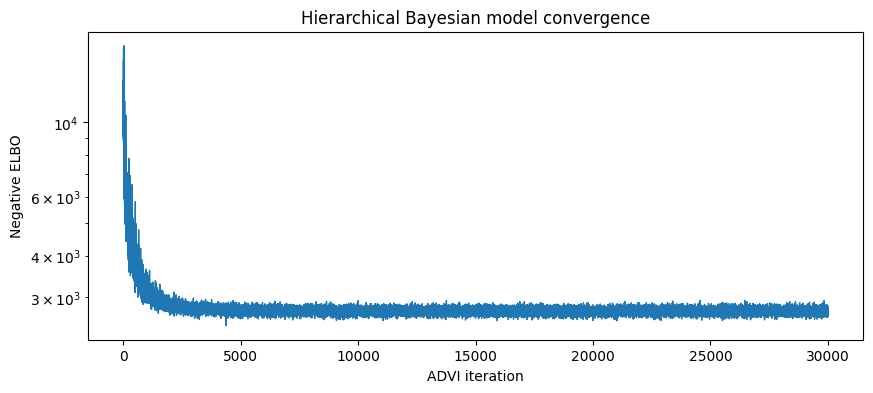

Inference data with groups:
	> posterior
	> observed_data


In [19]:
import matplotlib.pyplot as plt


plt.figure(figsize=(10, 4))
plt.plot(approximation.hist, linewidth=1)
plt.yscale("log")
plt.xlabel("ADVI iteration")
plt.ylabel("Negative ELBO")
plt.title("Hierarchical Bayesian model convergence")
plt.show()

with bayesian_model:
    bayesian_idata = approximation.sample(
        draws=POSTERIOR_DRAWS,
        random_seed=RANDOM_SEED,
        return_inferencedata=True,
    )

print(bayesian_idata)


## 11. Bayesian development predictions and metrics


In [20]:
posterior = bayesian_idata.posterior.stack(sample=("chain", "draw"))

intercept_draws = (
    posterior["intercept"]
    .transpose("sample")
    .values.astype(np.float32)
)
beta_draws = (
    posterior["beta"]
    .transpose("sample", "numeric_feature")
    .values.astype(np.float32)
)

category_effect_draws = {}
for column in categorical_feature_columns:
    safe = category_safe_names[column]
    dimension = f"{safe}_level"
    category_effect_draws[column] = (
        posterior[f"{safe}_effect"]
        .transpose("sample", dimension)
        .values.astype(np.float32)
    )

user_recency_slope_draws = None
if "user_recency_slopes" in ENABLED_BAYESIAN_EXTENSIONS:
    user_recency_slope_draws = (
        posterior["user_recency_slope"]
        .transpose("sample", "user_level")
        .values.astype(np.float32)
    )

token_learning_slope_draws = None
if "token_learning_slopes" in ENABLED_BAYESIAN_EXTENSIONS:
    token_learning_slope_draws = (
        posterior["token_learning_slope"]
        .transpose("sample", "skill_level")
        .values.astype(np.float32)
    )

user_format_effect_draws = None
if "user_format_slopes" in ENABLED_BAYESIAN_EXTENSIONS:
    user_format_effect_draws = (
        posterior["user_format_effect"]
        .transpose("sample", "user_level", "format_level")
        .values.astype(np.float32)
    )

user_mastery_factor_draws = None
skill_mastery_factor_draws = None
mastery_scale_draws = None
if "user_skill_mastery_low_rank" in ENABLED_BAYESIAN_EXTENSIONS:
    user_mastery_factor_draws = (
        posterior["user_mastery_factor"]
        .transpose("sample", "user_level", "mastery_latent_dimension")
        .values.astype(np.float32)
    )
    skill_mastery_factor_draws = (
        posterior["skill_mastery_factor"]
        .transpose("sample", "skill_level", "mastery_latent_dimension")
        .values.astype(np.float32)
    )
    mastery_scale_draws = (
        posterior["mastery_scale"]
        .transpose("sample")
        .values.astype(np.float32)
    )

n_dev = len(dev_features)
bayes_probability = np.empty(n_dev, dtype=np.float32)
bayes_probability_sd = np.empty(n_dev, dtype=np.float32)
bayes_probability_lower = np.empty(n_dev, dtype=np.float32)
bayes_probability_upper = np.empty(n_dev, dtype=np.float32)

for start in range(0, n_dev, PREDICTION_CHUNK_SIZE):
    stop = min(start + PREDICTION_CHUNK_SIZE, n_dev)

    logits = (
        intercept_draws[:, None]
        + beta_draws @ X_dev_bayes[start:stop].T
    )

    for column in categorical_feature_columns:
        indices = dev_category_indices[column][start:stop]
        logits += category_effect_draws[column][:, indices]

    if user_recency_slope_draws is not None:
        user_indices = dev_category_indices["user"][start:stop]
        recency_index = numeric_feature_index[
            "log1p_time_since_last_exposure"
        ]
        logits += (
            user_recency_slope_draws[:, user_indices]
            * X_dev_bayes[start:stop, recency_index][None, :]
        )

    if token_learning_slope_draws is not None:
        skill_indices = dev_category_indices["skill"][start:stop]
        exposure_index = numeric_feature_index["log1p_prior_exposures"]
        logits += (
            token_learning_slope_draws[:, skill_indices]
            * X_dev_bayes[start:stop, exposure_index][None, :]
        )

    if user_format_effect_draws is not None:
        user_indices = dev_category_indices["user"][start:stop]
        format_indices = dev_category_indices["format"][start:stop]
        logits += user_format_effect_draws[
            :, user_indices, format_indices
        ]

    if user_mastery_factor_draws is not None:
        user_indices = dev_category_indices["user"][start:stop]
        skill_indices = dev_category_indices["skill"][start:stop]
        user_factor = user_mastery_factor_draws[:, user_indices, :]
        skill_factor = skill_mastery_factor_draws[:, skill_indices, :]
        logits += (
            mastery_scale_draws[:, None]
            * np.sum(user_factor * skill_factor, axis=2)
            / np.sqrt(USER_SKILL_MASTERY_LATENT_DIM)
        )

    probability_draws = expit(logits)
    bayes_probability[start:stop] = probability_draws.mean(axis=0)
    bayes_probability_sd[start:stop] = probability_draws.std(axis=0)
    bayes_probability_lower[start:stop] = np.quantile(
        probability_draws, 0.025, axis=0
    )
    bayes_probability_upper[start:stop] = np.quantile(
        probability_draws, 0.975, axis=0
    )

print(f"Bayesian AUROC: {roc_auc_score(y_dev, bayes_probability):.6f}")
print(f"Bayesian PR-AUC: {average_precision_score(y_dev, bayes_probability):.6f}")
print(f"Bayesian Brier:  {brier_score_loss(y_dev, bayes_probability):.6f}")


Bayesian AUROC: 0.802008
Bayesian PR-AUC: 0.517183
Bayesian Brier:  0.114522


In [21]:
BAYES_IDATA_PATH = PROCESSED_DIR / "fr_en_bayesian_posterior.nc"
BAYES_PREDICTION_PATH = PROCESSED_DIR / "fr_en_dev_bayesian_predictions.parquet"
BAYES_PRED_PATH = PROCESSED_DIR / "fr_en_dev_bayesian.pred"
BAYES_NUMERIC_PIPELINE_PATH = PROCESSED_DIR / "fr_en_bayesian_numeric_pipeline.joblib"

az.to_netcdf(bayesian_idata, BAYES_IDATA_PATH)
joblib.dump(bayes_numeric_pipeline, BAYES_NUMERIC_PIPELINE_PATH)

bayesian_predictions = pd.DataFrame(
    {
        "instance_id": dev_features["instance_id"],
        "label": y_dev,
        "probability": bayes_probability,
        "posterior_sd": bayes_probability_sd,
        "lower_95": bayes_probability_lower,
        "upper_95": bayes_probability_upper,
    }
)
bayesian_predictions.to_parquet(BAYES_PREDICTION_PATH, index=False)
bayesian_predictions[["instance_id", "probability"]].to_csv(
    BAYES_PRED_PATH,
    sep=" ",
    header=False,
    index=False,
)

print(BAYES_IDATA_PATH)
print(BAYES_PREDICTION_PATH)


C:\Users\Richard\Desktop\school\Bayesian Machine Learning\project\english - french\processed\fr_en_bayesian_posterior.nc
C:\Users\Richard\Desktop\school\Bayesian Machine Learning\project\english - french\processed\fr_en_dev_bayesian_predictions.parquet


## Changing the model

To disable causal user ability, edit the configuration cell:

```python
ENABLED_FEATURE_BLOCKS = [
    "linguistic",
    "skill_history",
    "forgetting_curve",
    "global_skill_difficulty",
]
```

To enable session/fatigue features:

```python
ENABLED_FEATURE_BLOCKS = [
    "linguistic",
    "skill_history",
    "forgetting_curve",
    "causal_user_ability",
    "global_skill_difficulty",
    "session_fatigue",
]
```

Restart the kernel and run all cells after changing the list. No other feature or model lists need manual editing.


## Bayesian extension switches

The structural extensions are intentionally disabled by default so the global-difficulty model remains the control. Enable and evaluate one at a time:

```python
ENABLED_BAYESIAN_EXTENSIONS = [
    "user_recency_slopes",
    # "user_format_slopes",
    # "token_pos_hierarchy",
    # "morphology_hierarchy",
    # "token_learning_slopes",
    # "user_skill_mastery_low_rank",
]
```

`user_recency_slopes` is the implementation of user-specific forgetting rates. `token_learning_slopes` lets exposure effects vary by token. `user_skill_mastery_low_rank` represents a partially pooled user-by-skill interaction with a low-rank factorization rather than an enormous dense parameter matrix.

Recommended experiment order:

1. Forgetting-curve columns with no Bayesian extensions.
2. User recency slopes.
3. Token learning slopes.
4. POS-grouped token hierarchy.
5. Hierarchical morphology effects.
6. User-format slopes.
7. Low-rank user-skill mastery.

Keep only extensions that improve held-out AUROC, PR-AUC, or Brier score. Restart the kernel and run all cells after changing the extension list.
